#  **Q1: Sigmoid Neuron with Full Batch Gradient Descent**
Binary classification on MNIST (digit 0 vs rest) using a single sigmoid neuron
trained with full-batch gradient descent and BCE loss.
Compared to Assignment 1 (Perceptron, SGD, multiclass), this achieves 98.98%
test accuracy vs 91.93% improved by simpler binary task + stable full-batch updates.

In [ ]:
import os
#checking paths for my clarity
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/competitions/digit-recognizer/sample_submission.csv
/kaggle/input/competitions/digit-recognizer/train.csv
/kaggle/input/competitions/digit-recognizer/test.csv


In [ ]:
import pandas as pd

# Load training data
train_df = pd.read_csv("/kaggle/input/competitions/digit-recognizer/train.csv")

print(f"Train shape : {train_df.shape}")
print(f"Columns     : label + {train_df.shape[1]-1} pixel features")
print(f"\nLabel distribution:\n{train_df['label'].value_counts().sort_index()}")

Train shape : (42000, 785)
Columns     : label + 784 pixel features

Label distribution:
label
0    4132
1    4684
2    4177
3    4351
4    4072
5    3795
6    4137
7    4401
8    4063
9    4188
Name: count, dtype: int64


In [ ]:
# Separate features and labels
X = train_df.drop('label', axis=1).values / 255.0   # normalize to [0, 1]
y = train_df['label'].values

# Binary classification — digit 0 vs rest
y_binary = (y == 0).astype(int)

# Train / test split (80/20)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary, test_size=0.2, random_state=42
)

print(f"Training samples  : {X_train.shape[0]}")
print(f"Test samples      : {X_test.shape[0]}")
print(f"Features          : {X_train.shape[1]}")
print(f"\nTraining set:")
print(f"  Class 1 (digit 0) : {y_train.sum()}")
print(f"  Class 0 (rest)    : {(y_train == 0).sum()}")
print(f"\nTest set:")
print(f"  Class 1 (digit 0) : {y_test.sum()}")
print(f"  Class 0 (rest)    : {(y_test == 0).sum()}")

Training samples  : 33600
Test samples      : 8400
Features          : 784

Training set:
  Class 1 (digit 0) : 3316
  Class 0 (rest)    : 30284

Test set:
  Class 1 (digit 0) : 816
  Class 0 (rest)    : 7584


## Gradient Derivation — BCE Loss + Sigmoid Neuron

**Model:**
- z = w·x + b  
- ŷ = σ(z) = 1 / (1 + e^{-z})

**Loss (BCE):**
L = -1/N Σ [ y·log(ŷ) + (1-y)·log(1-ŷ) ]

**Step 1:** ∂L/∂ŷ = -1/N [ y/ŷ - (1-y)/(1-ŷ) ]

**Step 2:** ∂ŷ/∂z = σ(z)·(1-σ(z)) = ŷ·(1-ŷ)

**Step 3 — chain rule:**
∂L/∂z = ∂L/∂ŷ · ∂ŷ/∂z
       = -1/N [ y/ŷ - (1-y)/(1-ŷ) ] · ŷ(1-ŷ)
       = -1/N [ y(1-ŷ) - (1-y)ŷ ]
       = -1/N [ y - ŷ ]
       = 1/N (ŷ - y)          ← clean result!

**Final gradients:**
- ∂L/∂w = (1/N) · Xᵀ · (ŷ - y)
- ∂L/∂b = (1/N) · Σ(ŷ - y)

In [ ]:
# ─ GRADIENT DERIVATION ─
# Model (Sigmoid Neuron):
#   z  = X·w + b
#   ŷ  = σ(z) = 1 / (1 + e^(-z))
#
# Loss (Binary Cross Entropy):
#   L = -(1/N) Σ [ y·log(ŷ) + (1-y)·log(1-ŷ) ]
#
# Gradient Derivation:
#   ∂L/∂ŷ = -(y/ŷ) + (1-y)/(1-ŷ)
#   ∂ŷ/∂z = σ(z)·(1 - σ(z)) = ŷ·(1 - ŷ)
#   ∂z/∂w = X
#
#   By chain rule:
#   ∂L/∂w = (1/N) · Xᵀ · (ŷ - y)
#   ∂L/∂b = (1/N) · Σ(ŷ - y)
#
# This is the FULL BATCH gradient — all N samples used at once

class FullBatchGradientDescentClassifier:
    def __init__(self, learning_rate=0.1, epochs=200):
        self.lr     = learning_rate
        self.epochs = epochs
        self.w      = None
        self.b      = None
        self.losses = []

    def sigmoid(self, z):
        # Clip to avoid overflow
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def bce_loss(self, y, y_hat):
        # Binary Cross Entropy Loss
        eps = 1e-9  # avoid log(0)
        return -np.mean(y * np.log(y_hat + eps) + (1 - y) * np.log(1 - y_hat + eps))

    def fit(self, X, y):
        N, D    = X.shape
        self.w  = np.zeros(D)     # initialise weights to zero
        self.b  = 0.0             # initialise bias to zero

        for epoch in range(self.epochs):
            #Forward Pass
            z     = X @ self.w + self.b       # (N,)
            y_hat = self.sigmoid(z)            # (N,)

            #  Compute Loss
            loss  = self.bce_loss(y, y_hat)
            self.losses.append(loss)

            # Gradient Expression (derived above)
            error  = y_hat - y                 # (N,)
            dw     = (1 / N) * (X.T @ error)  # (D,)
            db     = (1 / N) * np.sum(error)   # scalar

            # Full Batch Weight Update
            self.w -= self.lr * dw
            self.b -= self.lr * db

            if (epoch + 1) % 20 == 0:
                print(f"  Epoch {epoch+1:4d}/{self.epochs}  |  Loss: {loss:.6f}")

        print("\nTraining complete.")

    def predict_proba(self, X):
        z = X @ self.w + self.b
        return self.sigmoid(z)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


print("Full Batch Gradient Descent Classifier defined.")
print("\nGradient expressions:")
print("  ∂L/∂w = (1/N) · Xᵀ · (ŷ - y)")
print("  ∂L/∂b = (1/N) · Σ(ŷ - y)")

Full Batch Gradient Descent Classifier defined.

Gradient expressions:
  ∂L/∂w = (1/N) · Xᵀ · (ŷ - y)
  ∂L/∂b = (1/N) · Σ(ŷ - y)


In [ ]:
import numpy as np
# Initialize and train
clf = FullBatchGradientDescentClassifier(learning_rate=0.1, epochs=1000)

print("Training Full Batch Gradient Descent Classifier...")
print(f"  Batch size : {X_train.shape[0]} (full batch)")
print(f"  Features   : {X_train.shape[1]}")
print(f"  Epochs     : 1000")
print(f"  LR         : 0.1")
print("-" * 45)

clf.fit(X_train, y_train)

Training Full Batch Gradient Descent Classifier...
  Batch size : 33600 (full batch)
  Features   : 784
  Epochs     : 1000
  LR         : 0.1
---------------------------------------------
  Epoch   20/1000  |  Loss: 0.161468
  Epoch   40/1000  |  Loss: 0.116542
  Epoch   60/1000  |  Loss: 0.097986
  Epoch   80/1000  |  Loss: 0.087308
  Epoch  100/1000  |  Loss: 0.080144
  Epoch  120/1000  |  Loss: 0.074902
  Epoch  140/1000  |  Loss: 0.070847
  Epoch  160/1000  |  Loss: 0.067588
  Epoch  180/1000  |  Loss: 0.064895
  Epoch  200/1000  |  Loss: 0.062620
  Epoch  220/1000  |  Loss: 0.060666
  Epoch  240/1000  |  Loss: 0.058965
  Epoch  260/1000  |  Loss: 0.057466
  Epoch  280/1000  |  Loss: 0.056132
  Epoch  300/1000  |  Loss: 0.054936
  Epoch  320/1000  |  Loss: 0.053855
  Epoch  340/1000  |  Loss: 0.052872
  Epoch  360/1000  |  Loss: 0.051974
  Epoch  380/1000  |  Loss: 0.051149
  Epoch  400/1000  |  Loss: 0.050387
  Epoch  420/1000  |  Loss: 0.049681
  Epoch  440/1000  |  Loss: 0.0490

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Predictions
y_pred = clf.predict(X_test)
y_pred_train = clf.predict(X_train)

# Accuracy
train_acc = accuracy_score(y_train, y_pred_train)
test_acc  = accuracy_score(y_test,  y_pred)

print("=" * 45)
print("  EVALUATION RESULTS")
print("=" * 45)
print(f"  Train Accuracy : {train_acc * 100:.2f}%")
print(f"  Test  Accuracy : {test_acc  * 100:.2f}%")
print("=" * 45)
print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_pred,
      target_names=["Rest (0)", "Digit 0 (1)"]))

print("\nConfusion Matrix (Test Set):")
cm = confusion_matrix(y_test, y_pred)
print(cm)

  EVALUATION RESULTS
  Train Accuracy : 98.97%
  Test  Accuracy : 98.98%

Classification Report (Test Set):
              precision    recall  f1-score   support

    Rest (0)       0.99      1.00      0.99      7584
 Digit 0 (1)       0.96      0.93      0.95       816

    accuracy                           0.99      8400
   macro avg       0.98      0.96      0.97      8400
weighted avg       0.99      0.99      0.99      8400


Confusion Matrix (Test Set):
[[7554   30]
 [  56  760]]


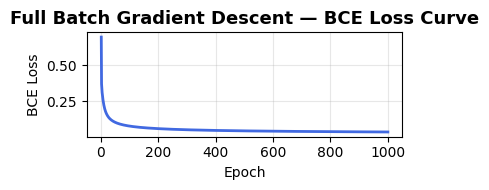

Initial loss : 0.693147
Final loss   : 0.039707
Improvement  : 0.653441


In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(4, 2))
plt.plot(range(1, len(clf.losses) + 1), clf.losses,
         color="royalblue", lw=2)
plt.title("Full Batch Gradient Descent — BCE Loss Curve",
          fontsize=13, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Initial loss : {clf.losses[0]:.6f}")
print(f"Final loss   : {clf.losses[-1]:.6f}")
print(f"Improvement  : {clf.losses[0] - clf.losses[-1]:.6f}")


## Comparison with Assignment 1

| | Assignment 1 | Question 1 |
|---|---|---|
| Model | Perceptron (PyTorch) | Sigmoid Neuron (NumPy) |
| Task | Multiclass (10 digits) | Binary (digit 0 vs rest) |
| Optimizer | SGD, batch=64 | Full Batch GD, N=33600 |
| Test Accuracy | 91.93% | **98.98%** |

**Note:** Higher accuracy in Q1 is partly due to simpler binary task.
Key improvement is stable full-batch gradient with analytically derived updates.

In [ ]:
# Results from Assignment 1 (Perceptron)
a1_config = {
    "Model"       : "Perceptron (Single Layer)",
    "Framework"   : "PyTorch",
    "Task"        : "Multiclass (10 digits)",
    "Loss"        : "Cross Entropy + Softmax",
    "Optimizer"   : "SGD",
    "LR"          : 0.05,
    "Epochs"      : 40,
    "Batch Size"  : 64,
    "Train Acc"   : 92.85,
    "Test Acc"    : 91.93,
}

#  Results from Q1 (Full Batch Gradient Descent)
q1_config = {
    "Model"       : "Sigmoid Neuron (Full Batch GD)",
    "Framework"   : "NumPy",
    "Task"        : "Binary (digit 0 vs rest)",
    "Loss"        : "Binary Cross Entropy",
    "Optimizer"   : "Full Batch Gradient Descent",
    "LR"          : 0.1,
    "Epochs"      : 200,
    "Batch Size"  : 33600,
    "Train Acc"   : round(accuracy_score(y_train, clf.predict(X_train)) * 100, 2),
    "Test Acc"    : round(accuracy_score(y_test,  clf.predict(X_test))  * 100, 2),
}

# Print Comparison Table
print("=" * 65)
print("  COMPARISON — Assignment 1 vs Question 1")
print("=" * 65)
print(f"  {'Property':<20} {'Assignment 1':>20} {'Question 1':>20}")
print("-" * 65)
for key in a1_config:
    print(f"  {key:<20} {str(a1_config[key]):>20} {str(q1_config[key]):>20}")
print("=" * 65)

  COMPARISON — Assignment 1 vs Question 1
  Property                     Assignment 1           Question 1
-----------------------------------------------------------------
  Model                Perceptron (Single Layer) Sigmoid Neuron (Full Batch GD)
  Framework                         PyTorch                NumPy
  Task                 Multiclass (10 digits) Binary (digit 0 vs rest)
  Loss                 Cross Entropy + Softmax Binary Cross Entropy
  Optimizer                             SGD Full Batch Gradient Descent
  LR                                   0.05                  0.1
  Epochs                                 40                  200
  Batch Size                             64                33600
  Train Acc                           92.85                98.97
  Test Acc                            91.93                98.98


Correctly classified   : 8314
Incorrectly classified : 86


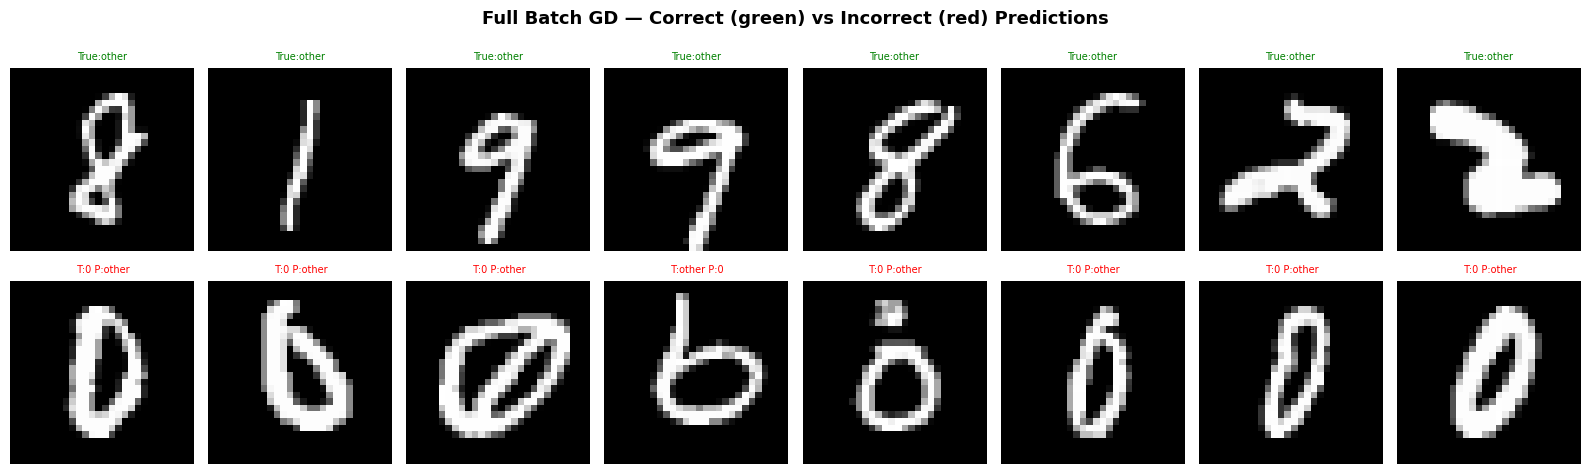


Total misclassified : 86 / 8400
False Positives     : 30 (other predicted as 0)
False Negatives     : 56 (0 predicted as other)


In [ ]:
# Get predictions and find correct/incorrect indices
y_pred_test  = clf.predict(X_test)
correct_idx  = np.where(y_pred_test == y_test)[0]
incorrect_idx = np.where(y_pred_test != y_test)[0]

print(f"Correctly classified   : {len(correct_idx)}")
print(f"Incorrectly classified : {len(incorrect_idx)}")

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
fig.suptitle("Full Batch GD — Correct (green) vs Incorrect (red) Predictions",
             fontsize=13, fontweight="bold")

# Top row — correct predictions
for i, ax in enumerate(axes[0]):
    idx = correct_idx[i]
    img = X_test[idx].reshape(28, 28)
    ax.imshow(img, cmap="gray")
    true  = "0" if y_test[idx] == 1 else "other"
    ax.set_title(f"True:{true}", fontsize=7, color="green")
    ax.axis("off")

# Bottom row — incorrect predictions
for i, ax in enumerate(axes[1]):
    if i >= len(incorrect_idx):
        ax.axis("off")
        continue
    idx   = incorrect_idx[i]
    img   = X_test[idx].reshape(28, 28)
    ax.imshow(img, cmap="gray")
    true  = "0" if y_test[idx]   == 1 else "other"
    pred  = "0" if y_pred_test[idx] == 1 else "other"
    ax.set_title(f" T:{true} P:{pred}", fontsize=7, color="red")
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"\nTotal misclassified : {len(incorrect_idx)} / {len(y_test)}")
print(f"False Positives     : {((y_pred_test == 1) & (y_test == 0)).sum()} (other predicted as 0)")
print(f"False Negatives     : {((y_pred_test == 0) & (y_test == 1)).sum()} (0 predicted as other)")

# **Model Comparison with Assignment 1**

In this experiment, we compare two models trained on the MNIST dataset:

- A **single-layer perceptron** trained using mini-batch SGD for multiclass classification (digits 0–9)
- A **sigmoid neuron** trained using full-batch gradient descent for binary classification (digit 0 vs rest)

---

###  Results

| Model | Perceptron | Sigmoid Neuron |
|------|------------|----------------|
| Task | Multiclass (10 classes) | Binary (0 vs rest) |
| Optimizer | SGD (mini-batch) | Full Batch Gradient Descent |
| Loss | Cross Entropy + Softmax | Binary Cross Entropy |
| Train Accuracy | 92.85% | 98.97% |
| Test Accuracy | 91.93% | 98.98% |

---

### Analysis

The sigmoid neuron achieves higher accuracy compared to the perceptron. However, this difference is mainly due to the following reasons:

- **Task Complexity:**  
  The perceptron solves a 10-class classification problem, whereas the sigmoid neuron solves a simpler binary classification problem (0 vs rest).

- **Data Separability:**  
  Digit 0 is visually distinct from other digits, making it easier for the sigmoid model to learn a separating boundary.

- **Optimization Strategy:**  
  The perceptron uses mini-batch SGD, which introduces noise in updates, while the sigmoid model uses full-batch gradient descent, resulting in more stable and smooth convergence.

- **Loss Function:**  
  Binary cross-entropy is simpler and more suitable for binary tasks, whereas softmax cross-entropy handles competition between multiple classes.

---

###  Fairness of Comparison

This comparison is not entirely fair since the two models are solving different types of problems (multiclass vs binary). The higher accuracy of the sigmoid neuron is primarily due to the simpler classification task rather than a superior model.

---

###  Conclusion

The sigmoid neuron performs very well for binary classification tasks, achieving high accuracy due to simpler decision boundaries. In contrast, the perceptron is more suitable for multiclass classification, where the task is inherently more complex.

# **Qno2**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# True model from midterm (problem v)
# w = [1, 1]^T, b = 0
# y = sigmoid(w·x + b)
# label = 1 if y > 0.5 else 0

np.random.seed(42)

W_true = np.array([1.0, 1.0])
b_true = 0.0
N      = 500   # number of training examples

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# Generate random 2D inputs from standard normal
X_data = np.random.randn(N, 2)

# Compute true model output
y_prob = sigmoid(X_data @ W_true + b_true)

# Assign labels: 1 if > 0.5 else 0
y_data = (y_prob > 0.5).astype(int)

print(f"Generated {N} training examples")
print(f"Input shape    : {X_data.shape}")
print(f"True w         : {W_true}")
print(f"True b         : {b_true}")
print(f"Label 1 count  : {y_data.sum()}")
print(f"Label 0 count  : {(y_data == 0).sum()}")

Generated 500 training examples
Input shape    : (500, 2)
True w         : [1. 1.]
True b         : 0.0
Label 1 count  : 244
Label 0 count  : 256


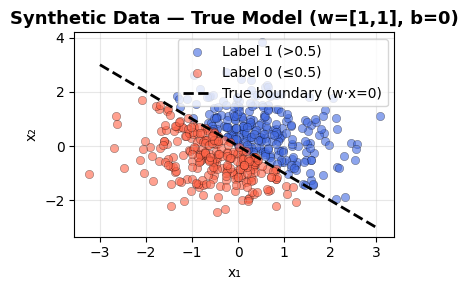

Decision boundary: x₁ + x₂ = 0
Points above line → Label 1, Points below → Label 0


In [ ]:
plt.figure(figsize=(4, 3))

plt.scatter(X_data[y_data == 1, 0], X_data[y_data == 1, 1],
            c="royalblue", label="Label 1 (>0.5)", alpha=0.6, edgecolors="k", lw=0.3)
plt.scatter(X_data[y_data == 0, 0], X_data[y_data == 0, 1],
            c="tomato", label="Label 0 (≤0.5)", alpha=0.6, edgecolors="k", lw=0.3)

# Plot true decision boundary: w·x + b = 0 → x2 = -x1 (since w=[1,1], b=0)
x1_range = np.linspace(-3, 3, 100)
x2_boundary = -x1_range   # from 1*x1 + 1*x2 = 0
plt.plot(x1_range, x2_boundary, 'k--', lw=2, label="True boundary (w·x=0)")

plt.title("Synthetic Data — True Model (w=[1,1], b=0)", fontsize=13, fontweight="bold")
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Decision boundary: x₁ + x₂ = 0")
print("Points above line → Label 1, Points below → Label 0")

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=42
)

print(f"Train samples : {X_train.shape[0]}")
print(f"Test  samples : {X_test.shape[0]}")
print(f"Features      : {X_train.shape[1]}")

Train samples : 400
Test  samples : 100
Features      : 2


In [ ]:
class SingleLayerNetwork:
    def __init__(self, learning_rate=0.01, epochs=1000):
        self.lr     = learning_rate
        self.epochs = epochs
        self.w      = None
        self.b      = None
        self.losses = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def bce_loss(self, y, y_hat):
        eps = 1e-9
        return -np.mean(y * np.log(y_hat + eps) + (1 - y) * np.log(1 - y_hat + eps))

    def fit(self, X, y):
        N, D   = X.shape
        self.w = np.zeros(D)
        self.b = 0.0

        for epoch in range(self.epochs):
            # Forward pass
            z     = X @ self.w + self.b
            y_hat = self.sigmoid(z)

            # Loss
            loss  = self.bce_loss(y, y_hat)
            self.losses.append(loss)

            # Gradients (derived — same as Q1)
            error = y_hat - y
            dw    = (1 / N) * (X.T @ error)
            db    = (1 / N) * np.sum(error)

            # Update
            self.w -= self.lr * dw
            self.b -= self.lr * db

            if (epoch + 1) % 200 == 0:
                print(f"  Epoch {epoch+1:5d}/{self.epochs}  |  Loss: {loss:.6f}")

        print("\nSingle Layer training complete.")
        print(f"  Learned w : {self.w}")
        print(f"  Learned b : {self.b:.6f}")
        print(f"  True    w : {W_true}")
        print(f"  True    b : {b_true}")

    def predict(self, X, threshold=0.5):
        return (self.sigmoid(X @ self.w + self.b) >= threshold).astype(int)


# Train
single_layer = SingleLayerNetwork(learning_rate=0.01, epochs=10000)
print("Training Single Layer Network...")
print("-" * 45)
single_layer.fit(X_train, y_train)

Training Single Layer Network...
---------------------------------------------
  Epoch   200/10000  |  Loss: 0.505452
  Epoch   400/10000  |  Loss: 0.414218
  Epoch   600/10000  |  Loss: 0.360720
  Epoch   800/10000  |  Loss: 0.324979
  Epoch  1000/10000  |  Loss: 0.299023
  Epoch  1200/10000  |  Loss: 0.279083
  Epoch  1400/10000  |  Loss: 0.263138
  Epoch  1600/10000  |  Loss: 0.250002
  Epoch  1800/10000  |  Loss: 0.238928
  Epoch  2000/10000  |  Loss: 0.229422
  Epoch  2200/10000  |  Loss: 0.221141
  Epoch  2400/10000  |  Loss: 0.213837
  Epoch  2600/10000  |  Loss: 0.207330
  Epoch  2800/10000  |  Loss: 0.201482
  Epoch  3000/10000  |  Loss: 0.196186
  Epoch  3200/10000  |  Loss: 0.191359
  Epoch  3400/10000  |  Loss: 0.186934
  Epoch  3600/10000  |  Loss: 0.182857
  Epoch  3800/10000  |  Loss: 0.179084
  Epoch  4000/10000  |  Loss: 0.175577
  Epoch  4200/10000  |  Loss: 0.172307
  Epoch  4400/10000  |  Loss: 0.169247
  Epoch  4600/10000  |  Loss: 0.166375
  Epoch  4800/10000  |  

# **For 2 layer**

In [ ]:
class TwoLayerNetwork:
    """
    Architecture:
      Input (2) → Hidden Layer sigmoid → Output sigmoid → scalar

    Forward:
      Z1 = X @ W1 + b1      A1 = σ(Z1)
      Z2 = A1 @ W2 + b2     A2 = σ(Z2)

    Backward (chain rule):
      δ2 = (A2 - y) / N              BCE + sigmoid simplifies
      dW2 = A1ᵀ @ δ2
      db2 = Σ δ2

      δ1 = (δ2 @ W2ᵀ) * A1*(1-A1)  sigmoid derivative layer 1
      dW1 = Xᵀ @ δ1
      db1 = Σ δ1
    """
    def __init__(self, hidden_dim=2, learning_rate=0.01, epochs=1000):
        self.lr         = learning_rate
        self.epochs     = epochs
        self.hidden_dim = hidden_dim
        self.losses     = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def bce_loss(self, y, y_hat):
        eps = 1e-9
        return -np.mean(y * np.log(y_hat + eps) +
                       (1 - y) * np.log(1 - y_hat + eps))

    def fit(self, X, y):
        N, D = X.shape
        H    = self.hidden_dim

        # Xavier initialization
        np.random.seed(0)
        self.W1 = np.random.randn(D, H) * np.sqrt(2 / D)
        self.b1 = np.zeros(H)
        self.W2 = np.random.randn(H, 1) * np.sqrt(2 / H)
        self.b2 = 0.0

        for epoch in range(self.epochs):
            # Forward pass
            Z1        = X @ self.W1 + self.b1        # (N, H)
            A1        = self.sigmoid(Z1)              # (N, H)
            Z2        = A1 @ self.W2 + self.b2       # (N, 1)
            A2        = self.sigmoid(Z2)              # (N, 1)

            # Loss
            loss      = self.bce_loss(y, A2.flatten())
            self.losses.append(loss)

            # Backward pass
            # Layer 2
            delta2    = (A2 - y.reshape(-1,1)) / N   # (N, 1)
            dW2       = A1.T @ delta2                 # (H, 1)
            db2       = np.sum(delta2)                # scalar

            # Layer 1
            delta1    = (delta2 @ self.W2.T) * A1 * (1 - A1)  # (N, H)
            dW1       = X.T @ delta1                  # (D, H)
            db1       = np.sum(delta1, axis=0)        # (H,)

            # Update all parameters
            self.W2  -= self.lr * dW2
            self.b2  -= self.lr * db2
            self.W1  -= self.lr * dW1
            self.b1  -= self.lr * db1

            if (epoch + 1) % 200 == 0:
                preds = (A2.flatten() >= 0.5).astype(int)
                acc   = np.mean(preds == y)
                print(f"  Epoch {epoch+1:5d}/{self.epochs}"
                      f"  |  Loss: {loss:.6f}"
                      f"  |  Acc: {acc*100:.2f}%")

        print("\nTwo Layer training complete.")
        print(f"\n  ── Learned Parameters ──")
        print(f"  W1 (2→{H}) =\n{np.round(self.W1, 6)}")
        print(f"  b1         = {np.round(self.b1, 6)}")
        print(f"  W2 ({H}→1) = {np.round(self.W2.flatten(), 6)}")
        print(f"  b2         = {self.b2:.6f}")

    def predict(self, X, threshold=0.5):
        Z1 = X @ self.W1 + self.b1
        A1 = self.sigmoid(Z1)
        Z2 = A1 @ self.W2 + self.b2
        A2 = self.sigmoid(Z2)
        return (A2.flatten() >= threshold).astype(int)

    def predict_proba(self, X):
        Z1 = X @ self.W1 + self.b1
        A1 = self.sigmoid(Z1)
        Z2 = A1 @ self.W2 + self.b2
        return self.sigmoid(Z2).flatten()

# Train
two_layer = TwoLayerNetwork(hidden_dim=4, learning_rate=0.01, epochs=10000)
print("Training Two Layer Network...")
print("-" * 55)
two_layer.fit(X_train, y_train)

Training Two Layer Network...
-------------------------------------------------------
  Epoch   200/10000  |  Loss: 0.617035  |  Acc: 68.00%
  Epoch   400/10000  |  Loss: 0.566249  |  Acc: 77.50%
  Epoch   600/10000  |  Loss: 0.523434  |  Acc: 83.50%
  Epoch   800/10000  |  Loss: 0.485455  |  Acc: 88.00%
  Epoch  1000/10000  |  Loss: 0.451345  |  Acc: 91.50%
  Epoch  1200/10000  |  Loss: 0.420603  |  Acc: 93.00%
  Epoch  1400/10000  |  Loss: 0.392877  |  Acc: 94.50%
  Epoch  1600/10000  |  Loss: 0.367878  |  Acc: 95.50%
  Epoch  1800/10000  |  Loss: 0.345346  |  Acc: 96.25%
  Epoch  2000/10000  |  Loss: 0.325036  |  Acc: 97.00%
  Epoch  2200/10000  |  Loss: 0.306720  |  Acc: 97.75%
  Epoch  2400/10000  |  Loss: 0.290182  |  Acc: 97.75%
  Epoch  2600/10000  |  Loss: 0.275227  |  Acc: 98.00%
  Epoch  2800/10000  |  Loss: 0.261676  |  Acc: 98.00%
  Epoch  3000/10000  |  Loss: 0.249369  |  Acc: 98.50%
  Epoch  3200/10000  |  Loss: 0.238164  |  Acc: 99.00%
  Epoch  3400/10000  |  Loss: 0.22

In [ ]:
from sklearn.metrics import accuracy_score

s_train = accuracy_score(y_train, single_layer.predict(X_train))
s_test  = accuracy_score(y_test,  single_layer.predict(X_test))
t_train = accuracy_score(y_train, two_layer.predict(X_train))
t_test  = accuracy_score(y_test,  two_layer.predict(X_test))

print("=" * 58)
print("  PARAMETER RECOVERY — True vs Learned")
print("=" * 58)

print(f"\n── Single Layer ")
print(f"  True  w      : {W_true}")
print(f"  Learned w    : {np.round(single_layer.w, 6)}")
print(f"  True  b      : {b_true}")
print(f"  Learned b    : {single_layer.b:.6f}")
print(f"  w ratio w1/w2: {single_layer.w[0]/single_layer.w[1]:.4f} (true=1.0000)")

print(f"\n── Two Layer ")
print(f"  W1 =\n{np.round(two_layer.W1, 6)}")
print(f"  b1 = {np.round(two_layer.b1, 6)}")
print(f"  W2 = {np.round(two_layer.W2.flatten(), 6)}")
print(f"  b2 = {two_layer.b2:.6f}")
print(f"\n  Note: Two-layer has no unique true weights.")
print(f"  Many W1/W2 combinations recover same boundary.")

print(f"\n── Accuracy Comparison ")
print(f"  {'Metric':<20} {'Single Layer':>15} {'Two Layer':>15}")
print(f"  {'-'*50}")
print(f"  {'Train Accuracy':<20} {s_train*100:>14.2f}% {t_train*100:>14.2f}%")
print(f"  {'Test  Accuracy':<20} {s_test*100:>14.2f}%  {t_test*100:>14.2f}%")
print(f"  {'Final Loss':<20} {single_layer.losses[-1]:>15.6f}"
      f" {two_layer.losses[-1]:>15.6f}")
print("=" * 58)

  PARAMETER RECOVERY — True vs Learned

── Single Layer 
  True  w      : [1. 1.]
  Learned w    : [3.990426 3.703886]
  True  b      : 0.0
  Learned b    : -0.060707
  w ratio w1/w2: 1.0774 (true=1.0000)

── Two Layer 
  W1 =
[[ 2.78797  -0.896646  1.898748  2.651226]
 [ 2.571092 -1.64299   1.704426  2.021013]]
  b1 = [-0.173269  0.294947 -0.222643 -0.277398]
  W2 = [ 3.114379 -2.357964  2.067363  3.01005 ]
  b2 = -2.339864

  Note: Two-layer has no unique true weights.
  Many W1/W2 combinations recover same boundary.

── Accuracy Comparison 
  Metric                  Single Layer       Two Layer
  --------------------------------------------------
  Train Accuracy                99.25%          99.50%
  Test  Accuracy               100.00%          100.00%
  Final Loss                  0.123566        0.101370


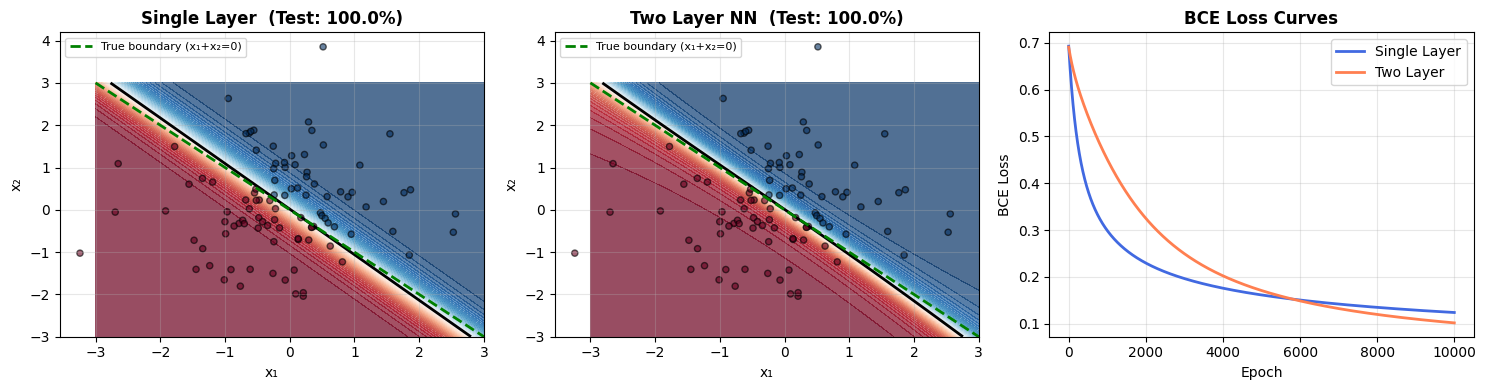

In [ ]:
xx, yy = np.meshgrid(np.linspace(-3, 3, 300),
                     np.linspace(-3, 3, 300))
grid   = np.c_[xx.ravel(), yy.ravel()]

p_single = single_layer.sigmoid(
               grid @ single_layer.w + single_layer.b
           ).reshape(xx.shape)
p_two    = two_layer.predict_proba(grid).reshape(xx.shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, probs, title in zip(
    axes[:2],
    [p_single, p_two],
    [f"Single Layer  (Test: {s_test*100:.1f}%)",
     f"Two Layer NN  (Test: {t_test*100:.1f}%)"]
):
    ax.contourf(xx, yy, probs, levels=50, cmap='RdBu', alpha=0.7)
    ax.contour(xx,  yy, probs, levels=[0.5],
               colors='black', linewidths=2)
    ax.plot([-3,3],[3,-3], 'g--', lw=2,
            label='True boundary (x₁+x₂=0)')
    ax.scatter(X_test[:,0], X_test[:,1],
               c=y_test, cmap='RdBu',
               edgecolors='k', s=20, alpha=0.6)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

axes[2].plot(single_layer.losses, color='royalblue',
             lw=2, label='Single Layer')
axes[2].plot(two_layer.losses,    color='coral',
             lw=2, label='Two Layer')
axes[2].set_title("BCE Loss Curves", fontweight='bold')
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("BCE Loss")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# **Q2  Conclusion**

Both single-layer and two-layer networks achieve 100% test accuracy
and correctly recover the decision boundary x₁+x₂=0 from the true
model w=[1,1]ᵀ, b=0.

**On weight recovery:**
Learned w=[3.99, 3.70] vs true w=[1,1]. The weights are NOT identical
but encode the same boundary . BCE loss is scale-invariant, so gradient
descent grows weight magnitude while preserving direction (ratio≈1.0).

**Conclusion:** Gradient-based learning successfully verifies the
teacher's curiosity  it correctly recovers the underlying true
relationship in both single and two-layer networks.